# Measuring US landfall

How strong storms are when they come ashore is a check of CHAZ against observations on the
US coast. This notebook counts US Atlantic and Gulf landfalls over 1981–2019 for IBTrACS, the CHAZ
team's ERA5 set and two of our ERA5 runs: 'shipped', with the public code's settings, which our
runs use, and 'refit-basin', the option [intensity.ipynb](intensity.ipynb) tests furthest.

The other notebooks count landfalls by the first-crossing rule of Emanuel (2025), which John et al.
(2026) also use when they test CHAZ: each storm counts once, at its first crossing from sea onto
land, at the wind interpolated to the time of the crossing. `ocr.risks.hurricane.landfall` finds
the crossing on hourly positions over the Natural Earth 1:10m US outline at 1/24°, where a cell is
US land if any part of the US falls in it, so the Florida Keys count. It times the crossing to 10
minutes and interpolates the 6-hourly winds to that time. Our version differs from his as follows:

- He counts crossings of coastal gates, line segments along the coast; we count the first time a
  track's centre is on US land.
- His landfall test is the distribution of crossings among a coast's gates, normalized to the
  observed total. He judges the coast's total by the model's share of basin storms that cross it
  over the observed share. The Poisson band on coast totals in section 2 is our extension.
- He has no landfall metric at major-hurricane strength; the 96 kt rows here are ours.
- His storms are those whose lifetime maximum exceeds 40 kt, in the basin where they first reach
  40 kt, over 1979–2023. Here a landfall counts from 34 kt, North Atlantic storms are those that
  reach 34 kt anywhere in the basin, and the years are 1981–2019.

Neither the 6-hourly IBTrACS records nor CHAZ gives the wind at the moment of landfall. Observed tracks have a wind every 6 hours.
CHAZ predicts intensity every 12 hours and stores the mean of two predictions at the node between
them. The wind interpolated to the crossing time takes part of the next node's wind, which is often
over land and weaker, and Emanuel (2025, section 5, point 9) notes that interpolation near landfall
can affect observed and synthetic winds differently. Section 3 measures this with two other
readings of the wind: the last wind over water before the first crossing, and the last wind over
water before each storm's strongest crossing, both on the track's 12-hourly steps. Section 1 also gives the rule of Lee et al. (2018),
which counts every landfall at least 100 km and 6 hours from the last one counted, on tracks
interpolated to 15 minutes and a 0.5° land mask (theirs from topography, ours from Natural Earth),
and the strongest wind within 300 km of US land east of 105°W. Rates are per year, and CHAZ's per
member-year (400 members a year).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from ocr.risks.hurricane import landfall, store

R = 'TCGI_CRH_PI'
NAMES = {
    'IBTrACS': 'ibtracs',
    'CHAZ team': 'published',
    'shipped': f'ours_{R}',
    'refit-basin': f'ours_{R}-land-fine-intensity-refit-basin',
}
COLORS = {
    'IBTrACS': '#52514e',
    'CHAZ team': '#eb6834',
    'shipped': '#2a78d6',
    'refit-basin': '#1baf7a',
}
SET = 'shipped'
THRESHOLDS = (34, 64, 96)
YEARS = landfall.YEARS[1] - landfall.YEARS[0] + 1
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)
rows = {
    name: pd.read_parquet(store.path(f'{landfall.OUT}/rows_{key}.parquet'))
    for name, key in NAMES.items()
}
lee = {
    name: pd.read_parquet(store.path(f'{landfall.OUT}/lee_{key}.parquet'))
    for name, key in NAMES.items()
}
members = {
    name: 1 if name == 'IBTrACS' else table.groupby('unit')['member'].nunique().sum()
    for name, table in rows.items()
}
member_years = {name: YEARS * count for name, count in members.items()}
pd.Series(members, name='members a year')

IBTrACS          1
CHAZ team      400
shipped        400
refit-basin    400
Name: members a year, dtype: int64

## 1. Five measures

The first table gives the rates and the second gives CHAZ over IBTrACS, with and without the scaling
to the observed North Atlantic storm count that the other notebooks apply.

In [2]:
PUBLISHED = 'first crossing, crossing-time wind (Emanuel 2025)'
FIRST_OFF = 'first crossing, last offshore wind'
OURS = 'strongest crossing, last offshore wind'
LEE = 'Lee et al. (2018), every landfall'
NEAR = f'within {landfall.NEAR_KM:.0f} km of US land east of 105°W'
COLUMN = {PUBLISHED: 'lf_wind', FIRST_OFF: 'lf_first_offshore_wind', OURS: 'lf_offshore_wind'}


def count(table, measure, threshold):
    """Landfalls at or above `threshold` kt in the landfall rows `table` by `measure`."""
    if measure in COLUMN:
        crossing = table.loc[landfall.atlantic_crossing(table), COLUMN[measure]]
        return int((crossing >= threshold).sum())
    if measure == LEE:
        return int(table[f'lee_{threshold}'].sum())
    return int((table['near_peak'] >= threshold).sum())


MEASURES = [PUBLISHED, FIRST_OFF, OURS, LEE, NEAR]
per_year = pd.DataFrame(
    {
        name: {
            (measure, f'≥ {threshold} kt'): count(table, measure, threshold) / member_years[name]
            for measure in MEASURES
            for threshold in THRESHOLDS
        }
        for name, table in rows.items()
    }
)
na = pd.Series({name: table['na_ts'].sum() / member_years[name] for name, table in rows.items()})
pd.concat([per_year, na.to_frame(('North Atlantic tropical storms', '')).T]).style.format(
    '{:.2f}'
).set_caption('US Atlantic and Gulf landfalls per year, 1981-2019 (CHAZ: per member-year)')

In [3]:
ratio = per_year.div(per_year['IBTrACS'], axis=0)
chaz = [k for k in NAMES if k != 'IBTrACS']
pd.concat(
    {
        'not scaled': ratio[chaz],
        'scaled to the observed NA storm count': ratio[chaz] * (na['IBTrACS'] / na[chaz]),
    },
    axis=1,
).style.format('{:.2f}').set_caption('CHAZ over IBTrACS')

By the first-crossing rule, the shipped run makes 0.88 of the observed US landfalls at 34 kt and
above, 0.59 of the hurricane landfalls and 0.66 of the major ones, without the scaling (0.89, 0.60
and 0.67 with it). Refit-basin makes 1.00, 0.67 and 0.53, and the CHAZ team's set 0.68, 0.42 and
0.43. At 64 kt every other measure puts the shipped run closer to observed (0.67 to 0.83). At 96 kt
the two offshore readings do not (0.59 and 0.65 against 0.66), while the Lee et al. rule and the
300 km measure do (0.73 and 0.70). Section 3 takes the offshore readings apart.

## 2. Emanuel's tests, adapted

Emanuel's landfall test compares the distribution of crossings along a coast with the observed one,
the model's counts normalized to the observed total. His K′ is 1 where every observed count lies
within the 5th–95th percentile band of Poisson noise around the model's count, and falls the
further outside the band the observed counts lie; it counts only bins where both counts exceed 5.
With our four coastal regions as coarse gates:

In [4]:
GATES = list(landfall.ATLANTIC)


def by_coast(table, threshold):
    landed = table[landfall.atlantic_crossing(table) & (table['lf_wind'] >= threshold)]
    return landed['lf_region'].value_counts().reindex(GATES, fill_value=0)


def k_score(obs, syn):
    """Emanuel's (2025) K' over the bins where both counts exceed 5 (his equations 2-10)."""
    lower, upper = stats.poisson.ppf([0.05, 0.95], syn[:, None]).T
    eligible = (obs > 5) & (syn > 5)
    error = np.where(obs >= syn, np.maximum(obs - upper, 0), np.maximum(lower - obs, 0)) / syn
    score = max(1 - error[eligible].mean(), 0) if eligible.any() else np.nan
    return score, int(eligible.sum())


dist = {}
for name in chaz:
    for threshold in (34, 64):
        observed = by_coast(rows['IBTrACS'], threshold).to_numpy(float)
        synthetic = by_coast(rows[name], threshold).to_numpy(float)
        # normalized to the observed total, as Emanuel's gate counts are
        synthetic = synthetic * observed.sum() / synthetic.sum()
        score, n_regions = k_score(observed, synthetic)
        dist[(name, f'≥ {threshold} kt')] = {
            **dict(zip(GATES, synthetic)),
            "K'": score,
            'regions scored': n_regions,
        }
obs_dist = {
    ('IBTrACS', f'≥ {threshold} kt'): dict(zip(GATES, by_coast(rows['IBTrACS'], threshold)))
    for threshold in (34, 64)
}
pd.DataFrame({**obs_dist, **dist}).T.style.format('{:.1f}').format(
    '{:.0f}', subset=['regions scored']
).set_caption(
    'First-crossing US landfalls by coastal region, 1981-2019, CHAZ normalized to the observed total,'
    " and Emanuel's K' over regions with more than 5 events"
)

The table leaves out 96 kt: with 10 observed major landfalls, at most one region has more than 5.
Every CHAZ set scores 1 at 34 and 64 kt: once the totals match, CHAZ spreads its landfalls along
the coast as observed, within sampling noise. Four regions are much coarser than his gates.

The coast's total is a separate question. Emanuel scores it as the model's share of basin storms
crossing the coast over the observed share, and counts a ratio from 0.75 up to, but not including,
1.25 as good. The scaled first-crossing ratios of section 1 are the closest to it, though his basin
count takes storms where they first reach 40 kt. For the shipped run they are 0.89 at 34 kt,
inside that range, and 0.60 at 64 kt, below it.

The next table puts a Poisson band on the coast's totals, which Emanuel does not: the observed total
is taken as one draw from a Poisson distribution centred on the count the shipped run expects. The tail
p is the chance of a count at least as far from the expected count as the observed one, on the same
side of it; it describes the distance rather than testing a direction fixed in advance. The band
treats landfalls as independent. Clustering between years would widen it, and so would counting one
storm more than once, as the Lee et al. rule does.

In [5]:
per_member_year = members[SET]
PERIODS = {'1981-2019': (1981, 2019), '1981-1999': (1981, 1999), '2000-2019': (2000, 2019)}


def tail_p(observed, expected):
    """Chance of a Poisson(expected) count at least as far from `expected` as `observed`, on
    the side where `observed` lies."""
    if observed >= expected:
        return stats.poisson.sf(observed - 1, expected)
    return stats.poisson.cdf(observed, expected)


test = {}
for period, years in PERIODS.items():
    observed_rows = rows['IBTrACS'][rows['IBTrACS']['year'].between(*years)]
    synthetic_rows = rows[SET][rows[SET]['year'].between(*years)]
    scale = observed_rows['na_ts'].sum() / (synthetic_rows['na_ts'].sum() / per_member_year)
    for measure in MEASURES[:4] if period == '1981-2019' else [PUBLISHED, OURS]:
        for threshold in (64, 96):
            observed = count(observed_rows, measure, threshold)
            for scaling, factor in (('not scaled', 1.0), ('scaled', scale)):
                expected = count(synthetic_rows, measure, threshold) / per_member_year * factor
                lower, upper = stats.poisson.ppf([0.05, 0.95], expected)
                test[(period, measure, f'≥ {threshold} kt', scaling)] = {
                    'observed': observed,
                    f'{SET} expects': expected,
                    '5%': lower,
                    '95%': upper,
                    'inside': lower <= observed <= upper,
                    'tail p': tail_p(observed, expected),
                }
test = pd.DataFrame(test).T
test.style.format(
    {
        'observed': '{:.0f}',
        f'{SET} expects': '{:.1f}',
        '5%': '{:.0f}',
        '95%': '{:.0f}',
        'tail p': '{:.3f}',
    }
).set_caption(
    'Observed US Atlantic and Gulf landfall totals against the 5th-95th percentiles of a Poisson'
    f' distribution centred on the count {SET} expects'
)

By the first-crossing rule, the observed total over 1981–2019 lies above the band at 64 kt, scaled
or not: the shipped run expects 31.4 hurricane landfalls against 53 observed (tail p 0.000). At
96 kt it lies inside (6.6 expected against 10 observed, tail p 0.132). The hurricane shortfall is
larger in 1981–1999, with 27 observed against 13.4 expected (tail p 0.001); over 2000–2019, 26
against 18.0, it lies above the band unscaled (tail p 0.044) and inside it scaled (0.120). The
expected major counts of the halves, 2.4 to 4.3, are below the 5 that Emanuel's K-test requires.
By the Lee et al. rule the hurricane total also lies above the band (tail p 0.002) and the major
total inside it. Read at the last offshore wind, the hurricane totals still lie above the band, at
the first crossing (tail p 0.013) and at the strongest (0.029).

## 3. Which wind and which crossing

The first-crossing rule and the reading at each storm's strongest crossing and last offshore wind
differ in which crossing counts and in which wind is read. The table changes one at a time: first
the wind, from the wind at the crossing time to the last wind over water before the crossing, at
most 12 hours earlier. That wind is read on the track's 12-hourly steps, CHAZ's prediction steps
and, for IBTrACS, every second record from the first, so an IBTrACS record over water at the
step between is skipped; it counts only if the track stays over water from that step to the
crossing and the storm still has a wind at the crossing; then the crossing, from the first to the strongest.

In [6]:
steps = {}
for name in ('IBTrACS', SET):
    for threshold in (64, 96):
        steps[(name, f'≥ {threshold} kt')] = {
            measure: count(rows[name], measure, threshold) / members[name]
            for measure in (PUBLISHED, FIRST_OFF, OURS)
        }
steps = pd.DataFrame(steps).T
steps.style.format('{:.1f}').set_caption(
    'US Atlantic and Gulf landfalls 1981-2019 as the rule changes one step at a time'
    f' (CHAZ: per {members[SET]} members a year, so per 39 years)'
)

In [7]:
land = landfall.USLand()
records = landfall.landfall_records(landfall.ibtracs_csv(store.s3()), land)
hurdat = records.groupby('storm')['wind'].max()
observed_rows = rows['IBTrACS']
observed_rows = observed_rows[landfall.atlantic_crossing(observed_rows)].set_index('storm')
pd.DataFrame(
    {
        f'≥ {threshold} kt': {
            'HURDAT landfall records, each storm at its strongest': int(
                (hurdat >= threshold).sum()
            ),
            **{
                measure: int((observed_rows[COLUMN[measure]] >= threshold).sum())
                for measure in COLUMN
            },
        }
        for threshold in (64, 96)
    }
).style.set_caption('Observed storms with a US Atlantic or Gulf landfall, 1981-2019')

IBTrACS 20261112


,≥ 64 kt,≥ 96 kt
"HURDAT landfall records, each storm at its strongest",58,17
"first crossing, crossing-time wind (Emanuel 2025)",53,10
"first crossing, last offshore wind",52,15
"strongest crossing, last offshore wind",55,16


Reading the last offshore wind raises the observed major count from 10 to 15 and the shipped
run's from 6.6 to 8.9; counting the strongest crossing adds about one more to each (16 and 10.3).
At 64 kt the wind reading barely moves the observed count (53 to 52) but raises the shipped run's
from 31.4 to 37.2, and the strongest crossing takes it to 41.8. The wind reading moves CHAZ's
counts more than IBTrACS's. HURDAT's landfall records, counting each storm at its strongest
landfall, have 58 storms at 64 kt and 17 at 96 kt. They are a reference for the observed side only;
the first-crossing rule does not aim at a storm's strongest landfall.

One reason the wind reading could change the two records differently is their spacing in time. The
next table puts IBTrACS's winds in CHAZ's form: every other synoptic record kept, starting from the
first record or from the second, and each record between replaced by the mean of its two
neighbours. Positions stay 6-hourly, as CHAZ's are. The thinning from the second record drops each
track's first position. Thinning does not make IBTrACS like CHAZ in other ways: observed storms
keep their own tracks and lifetimes, while a CHAZ member can lose its wind while its track
continues.

In [8]:
def twelve_hourly(w):
    """Winds as CHAZ stores them: each odd node the mean of its two neighbours."""
    out = w.copy()
    out[:, 1:-1:2] = 0.5 * (w[:, :-2:2] + w[:, 2::2])
    if w.shape[1] % 2 == 0:
        out[:, -1] = np.nan
    return out


lat, lon, wind, season = landfall.observed_arrays(landfall.ibtracs_csv(store.s3()))
thinned = {
    start: landfall.storm_rows(
        lat[start:], lon[start:], twelve_hourly(wind[:, start:]), season, land, 'IBTrACS', 'ibtracs'
    )
    for start in (0, 1)
}
scale = rows['IBTrACS']['na_ts'].sum() / (rows[SET]['na_ts'].sum() / per_member_year)
spacing = {}
for measure in (PUBLISHED, LEE):
    for threshold in (64, 96):
        six_hourly = count(rows['IBTrACS'], measure, threshold)
        twelve = [count(thinned[start], measure, threshold) for start in (0, 1)]
        for scaling, factor in (('not scaled', 1.0), ('scaled', scale)):
            expected = count(rows[SET], measure, threshold) / per_member_year * factor
            lower, upper = stats.poisson.ppf([0.05, 0.95], expected)
            spacing[(measure, f'≥ {threshold} kt', scaling)] = {
                'IBTrACS 6-hourly': six_hourly,
                '12-hourly from node 0': twelve[0],
                '12-hourly from node 1': twelve[1],
                '12-hourly, mean': np.mean(twelve),
                f'{SET} expects': expected,
                '5%': lower,
                '95%': upper,
                'tail p, mean': tail_p(round(np.mean(twelve)), expected),
            }
spacing = pd.DataFrame(spacing).T
spacing.style.format('{:.0f}').format(
    '{:.1f}', subset=['12-hourly, mean', f'{SET} expects']
).format('{:.3f}', subset=['tail p, mean']).set_caption(
    "Observed US Atlantic and Gulf landfalls with IBTrACS's winds at 6 hours and thinned to CHAZ's"
    f' 12-hourly form, against the count {SET} expects'
)

IBTrACS 20261112


Thinning lowers the observed counts under both published rules. At 64 kt they stay above the
band: a mean of 47 against a band of 22 to 41 by the first-crossing rule, and 54.5 against 29 to 50
by the Lee et al. rule. At 96 kt they were inside it before thinning and stay there (7.5 against
6.6 expected, and 8.5 against 8.1). The spacing in time accounts for part of the gap at hurricane
strength, not all of it; the check does not say what causes the rest.

## 4. Lee et al. (2018)'s test

Lee et al. (2018, section 5.2) test CHAZ by coast with return-period curves of landfall intensity.
They count every independent landfall (their section 2.2, the Lee et al. rule of section 1), show
the spread of the model's realizations against the observed curve, and shift the curves so that the
rate at their lowest threshold, 35 kt, matches the observed one. Here a realization is one of
the shipped run's 400 members a year over 1981–2019, as theirs were 400 realizations of their period.
The Gulf coast is Texas to Alabama and Florida west of 81°W, and the Atlantic coast the rest, since
their regions' boundaries are not given; the shift is one factor per coast. The shading is the
0–100 and 25–75 percentile range of the realizations, and the line their mean. Their 2018
intensity model stopped storms right after landfall (their section 4.2), so their result need not
hold for the current code.

In [9]:
def coast_of(lon, region):
    gulf = (region == 'TX-AL') | ((region == 'FL') & (lon < -81.0))
    return np.where(gulf, 'Gulf coast', 'Atlantic coast')


LEVELS = np.arange(35, 151, 1.0)
COASTS = ['Gulf coast', 'Atlantic coast']


def exceedance(name):
    """(coast, realization, level) landfall counts over 1981-2019 at or above each level."""
    landfalls = lee[name]
    landfalls = landfalls.assign(
        coast=coast_of(landfalls['lon'].values, landfalls['region'].values),
        realization=landfalls['unit'] + ':' + landfalls['member'].astype(str),
    )
    units = rows[name]['unit'].unique()
    per_unit = members[name] // len(units)
    realizations = [f'{unit}:{member}' for unit in units for member in range(per_unit)]
    out = {}
    for coast in COASTS:
        on_coast = landfalls[landfalls['coast'] == coast]
        winds = {key: group['wind'].to_numpy() for key, group in on_coast.groupby('realization')}
        out[coast] = np.array(
            [
                [(winds.get(realization, np.empty(0)) >= level).sum() for level in LEVELS]
                for realization in realizations
            ],
            float,
        )
    return out


exc = {name: exceedance(name) for name in ('IBTrACS', SET, 'CHAZ team')}
obs35 = {coast: exc['IBTrACS'][coast][0, 0] for coast in COASTS}
pd.DataFrame(
    {name: {coast: counts[coast].shape[0] for coast in COASTS} for name, counts in exc.items()}
).style.set_caption('Realizations of 1981-2019 on each coast')

,IBTrACS,shipped,CHAZ team
Gulf coast,1,400,400
Atlantic coast,1,400,400


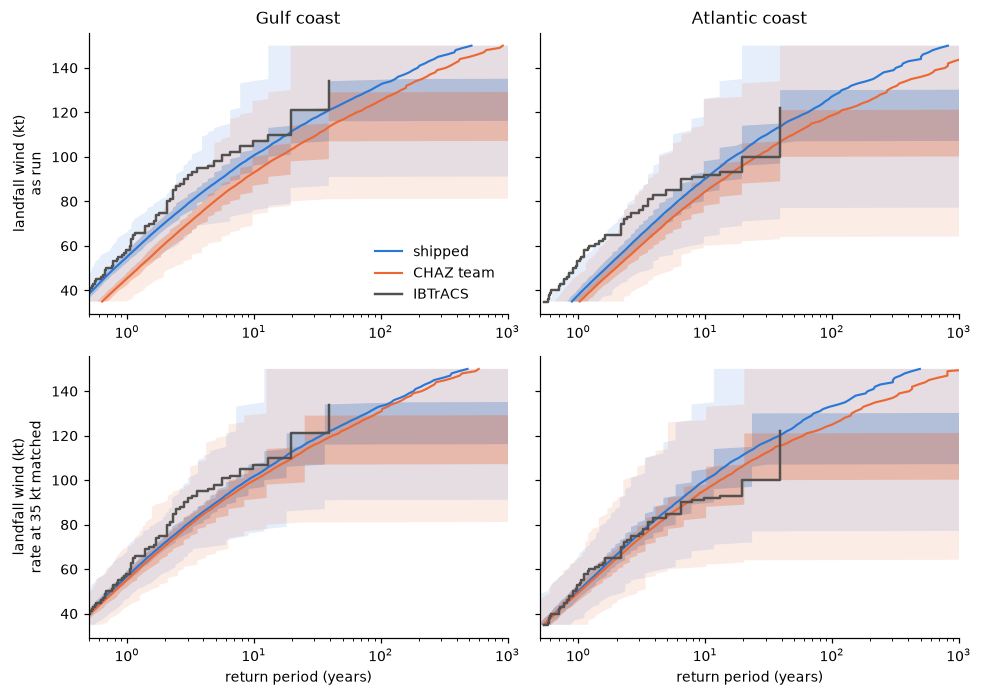

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6.4), sharey=True)


def period(rate):
    """Return period (years) of an exceedance rate (per year)."""
    return 1 / np.maximum(rate, 1e-9)


for col, coast in enumerate(COASTS):
    observed_rate = exc['IBTrACS'][coast][0] / YEARS
    for row, adjusted in enumerate((False, True)):
        ax = axes[row, col]
        for name in (SET, 'CHAZ team'):
            rate = exc[name][coast] / YEARS
            if adjusted:
                rate = rate * (obs35[coast] / YEARS) / rate[:, 0].mean()
            low, q25, q75, high = np.percentile(rate, [0, 25, 75, 100], axis=0)
            color = COLORS[name]
            ax.fill_betweenx(LEVELS, period(high), period(low), color=color, alpha=0.12, lw=0)
            ax.fill_betweenx(LEVELS, period(q75), period(q25), color=color, alpha=0.3, lw=0)
            ax.plot(period(rate.mean(axis=0)), LEVELS, color=color, lw=1.4, label=name)
        seen = observed_rate > 0
        ax.step(
            1 / observed_rate[seen],
            LEVELS[seen],
            color=COLORS['IBTrACS'],
            lw=1.6,
            where='post',
            label='IBTrACS',
        )
        ax.set_xscale('log')
        ax.set_xlim(0.5, 1000)
    axes[0, col].set_title(coast)
axes[0, 0].set_ylabel('landfall wind (kt)\nas run')
axes[1, 0].set_ylabel('landfall wind (kt)\nrate at 35 kt matched')
for ax in axes[1]:
    ax.set_xlabel('return period (years)')
axes[0, 0].legend(frameon=False, loc='lower right')
fig.tight_layout()

In [11]:
pct = {}
for coast in COASTS:
    observed = exc['IBTrACS'][coast][0]
    for adjusted in (False, True):
        ensemble = exc[SET][coast].copy()
        if adjusted:
            ensemble = ensemble * obs35[coast] / ensemble[:, 0].mean()
        for level in (35, 64, 83, 96, 113):
            i = int(np.searchsorted(LEVELS, level))
            below = (ensemble[:, i] < observed[i]).mean()
            equal = (ensemble[:, i] == observed[i]).mean()
            label = 'rate at 35 kt matched' if adjusted else 'as run'
            pct[(coast, label, f'≥ {level} kt')] = {
                'observed landfalls': observed[i],
                f'{SET} median': np.median(ensemble[:, i]),
                'observed percentile': 100 * (below + 0.5 * equal),
            }
pd.DataFrame(pct).T.style.format('{:.0f}').set_caption(
    f'Lee et al. (2018) landfalls, 1981-2019: observed count against the {exc[SET]["Gulf coast"].shape[0]}'
    f' realizations of {SET}, and its percentile among them'
)

On the Gulf coast the shipped run makes somewhat fewer landfalls than observed at 35 kt (the
observed count is at the 78th percentile of the realizations), and fewer strong ones: the observed
counts at 64, 83 and 96 kt lie at the 96th, 97th and 94th percentiles. With the rate at 35 kt
matched, they lie at the 87th, 93rd and 92nd. On the Atlantic coast the shipped run makes too few
landfalls (the observed count is at the 100th percentile at 35 and 64 kt); with the rate matched,
the observed counts lie between the 24th and 66th percentiles at the five thresholds in the table.
In Lee et al.'s terms, the shipped run underestimates landfall frequency on the Atlantic coast;
on the Gulf coast its strong landfalls are low in the spread of the realizations but within it once
the rate is matched. Without the adjustment, Lee et al. (2018) also found CHAZ making too few
landfalls on the Gulf of Mexico and eastern US coasts.

## Summary

By the first-crossing rule of Emanuel (2025), applied here to coast totals, the shipped run makes
0.88 of the observed US Atlantic and Gulf landfalls at 34 kt and above, 0.59 of the hurricane
landfalls and 0.66 of the major ones, without the North Atlantic scaling. The hurricane total lies
above the 5th–95th percentile band of Poisson noise around the count it expects; the major total
lies inside it. Normalized to the observed total, every CHAZ set's landfalls over the four coastal
regions lie within sampling noise of the observed ones (Emanuel's K′ of 1).

The hurricane shortfall holds however the wind is read near landfall: at each storm's strongest
crossing and last offshore wind, and with IBTrACS's winds thinned to CHAZ's 12-hour form, the
observed hurricane totals stay above the band. By Lee et al. (2018)'s test, the shipped run makes
too few landfalls on the Atlantic coast, and its strong Gulf landfalls are low but within the
spread of the realizations once the rate is matched.